<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/notebooks/baseline_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · 02 ·End-to-end baseline comparison

**Purpose:** establish reproducible, unweighted reference pipelines before experimenting with training-window selection or imbalance treatments.

Compare a constant-score DummyClassifier, logistic regression and LightGBM. All use months 0–4 for training and month 5 for validation. **Test evaluation is off by default**: months 6–7 remain for the agreed final comparisons. Validation metrics printed here are development results, not unbiased final generalization estimates after selection.

This notebook is standalone and loads the Parquet/JSON pair produced by `00_data_preparation.ipynb`. Run top to bottom. Use a CPU runtime. A full-data fit can take several minutes or longer depending on hardware; tuning multiplies that work. Comments explain the transformations and calculations. No results are pre-filled.


## 1. Configure the runtime and locations

Use the same project location as preparation. The raw CSV is not required for this notebook once the prepared pair exists.


In [ ]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'

CLEAN_PATH = PROCESSED_DIR / 'baf_clean.parquet'
MANIFEST_PATH = PROCESSED_DIR / 'preparation_manifest.json'

print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Python')
print('Project:', PROJECT_DIR)
print('Raw CSV:', RAW_PATH)
print('Prepared data:', CLEAN_PATH)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Runtime: Google Colab
Project: /content/drive/MyDrive/BT4012_grp_proj
Raw CSV: /content/drive/MyDrive/BT4012_grp_proj/Base.csv
Prepared data: /content/drive/MyDrive/BT4012_grp_proj/processed/baf_clean.parquet


## 2. Dependencies and experiment settings

Colab installs missing LightGBM/Parquet support. Local users should install `requirements.txt` first.

Start with `RUN_TUNING=False` to check the complete pipeline. Turn it on for a small predefined validation search once the run succeeds. The selection metric is **average precision (AP)**. No weighting or resampling is used here.

Each execution gets its own run directory. Model/prediction artifacts can be disabled to save space. Set `EVALUATE_TEST=True` only after agreeing on the configurations you intend to evaluate; this is a manual guard, not a restriction on reading the dataset.


In [ ]:
import importlib.util
import subprocess

required_packages = {'lightgbm': 'lightgbm>=4.0', 'pyarrow': 'pyarrow>=14.0'}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    if IN_COLAB:
        subprocess.check_call([
            sys.executable, '-m', 'pip', 'install', '-q', *missing_packages,
        ])
    else:
        raise ImportError('Missing dependencies. Run: python -m pip install -r requirements.txt')

import hashlib
import json
import platform
import time
import warnings
from datetime import datetime, timezone
from uuid import uuid4

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    average_precision_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

SEED = 42
N_JOBS = 2
RUN_TUNING = True
EVALUATE_TEST = False
SAVE_MODELS = True
SAVE_PREDICTIONS = True
VERIFY_CHECKSUM = True
FPR_TARGET = 0.05
REVIEW_CAPACITIES = [0.01, 0.02, 0.05]

# Keep the initial run reasonably small; increase only as a deliberate experiment.
LGBM_TREES = 300
LOGREG_MAX_ITER = 2000
RUN_LABEL = 'unweighted_baseline'

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
RUN_NAME = f'{RUN_LABEL}_{run_id}'
RESULTS_DIR = PROJECT_DIR / 'results' / 'baseline' / RUN_NAME
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts' / 'baseline' / RUN_NAME
FIGURES_DIR = RESULTS_DIR / 'figures'

for directory in [RESULTS_DIR, FIGURES_DIR, ARTIFACTS_DIR]:
    directory.mkdir(parents=True, exist_ok=False)

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 200,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

print('Results:', RESULTS_DIR)
print('Large artifacts:', ARTIFACTS_DIR)
print('Test evaluation enabled:', EVALUATE_TEST)


Results: /content/drive/MyDrive/BT4012_grp_proj/results/baseline/unweighted_baseline_20261115T161531Z_103e88
Large artifacts: /content/drive/MyDrive/BT4012_grp_proj/artifacts/baseline/unweighted_baseline_20261115T161531Z_103e88
Test evaluation enabled: False


## 3. Load the prepared contract and create chronological splits

Validate the prepared pair and use the manifest's ordered predictor list. `row_id`, the label and month are never inputs. The test split is loaded but its labels are not evaluated or summarised unless the final evaluation switch is enabled. Training/validation class counts are shown to verify development splits.


In [ ]:
def file_sha256(path):
    """Return a chunked SHA-256 digest to verify the prepared file matches its manifest."""
    digest = hashlib.sha256()

    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)

    return digest.hexdigest()


if not CLEAN_PATH.is_file() or not MANIFEST_PATH.is_file():
    raise FileNotFoundError('Run 00_data_preparation.ipynb first with the same project paths.')

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)

if manifest.get('schema_version') != 1:
    raise ValueError('Unsupported preparation manifest version.')

if VERIFY_CHECKSUM and file_sha256(CLEAN_PATH) != manifest['prepared_sha256']:
    raise ValueError('Parquet fingerprint differs from the manifest; rerun preparation.')

df = pd.read_parquet(CLEAN_PATH)
TARGET = manifest['target']
MONTH = manifest['month_column']
ROW_ID = manifest['row_id_column']
FEATURES = manifest['features']
NUMERICAL = manifest['numerical_features']
CATEGORICAL = manifest['categorical_features']

if len(df) != manifest['rows'] or list(df.columns) != manifest['columns']:
    raise ValueError('Prepared data dimensions/schema differ from the manifest.')

if not df[ROW_ID].is_unique:
    raise ValueError('row_id must uniquely identify source rows.')

if set(FEATURES) != set(NUMERICAL + CATEGORICAL):
    raise ValueError('Feature lists in the manifest are inconsistent.')

if set(FEATURES) & {TARGET, MONTH, ROW_ID}:
    raise ValueError('A target, time or identifier column was included as a predictor.')

# Keep categorical missing entries as np.nan for compatibility with sklearn.
for column in CATEGORICAL:
    df[column] = df[column].astype(object).where(df[column].notna(), np.nan)

train = df[df[MONTH].isin(manifest['split_months']['train'])].copy()
validation = df[df[MONTH].isin(manifest['split_months']['validation'])].copy()
test = df[df[MONTH].isin(manifest['split_months']['test'])].copy()

for split, frame in [('train', train), ('validation', validation), ('test', test)]:
    if len(frame) != manifest['split_counts'][split]:
        raise ValueError(f'{split} row count differs from the manifest.')

    # Label integrity checks do not select models or expose test performance.
    if not frame[TARGET].isin([0, 1]).all():
        raise ValueError(f'Invalid labels in {split}.')

if train[TARGET].nunique() != 2 or validation[TARGET].nunique() != 2:
    raise ValueError('Training and validation each need both classes.')

X_train = train[FEATURES]
y_train = train[TARGET].to_numpy()
X_validation = validation[FEATURES]
y_validation = validation[TARGET].to_numpy()

display(pd.DataFrame([
    {
        'split': name,
        'applications': len(frame),
        'frauds': int(frame[TARGET].sum()),
        'fraud_rate': frame[TARGET].mean(),
    }
    for name, frame in [('train', train), ('validation', validation)]
]))

print('Test applications reserved:', len(test))
print(f'Predictors: {len(NUMERICAL)} numeric + {len(CATEGORICAL)} categorical')


,split,applications,frauds,fraud_rate
0,train,675666,6740,0.009975
1,validation,119323,1411,0.011825


Test applications reserved: 205011
Predictors: 24 numeric + 5 categorical


## 4. Define comparable model-specific pipelines

**Logistic regression:** training-median imputation + missing indicators, numeric scaling, and one-hot categorical encoding. Unknown future categories produce all-zero one-hot indicators. `keep_empty_features=True` retains numeric columns even if an eventual smaller training subset has no observed values.

**LightGBM:** numeric NaNs pass through unchanged. Categories are imputed to an explicit missing label, encoded using a vocabulary fitted on training rows, and **explicitly marked categorical to LightGBM**. Integer codes do not imply ordinal meaning. An unseen category becomes −1, which LightGBM treats as missing. Scaling is unnecessary.

**Dummy:** emits the training class prevalence for every application; it is a no-skill reference, not a deployable ranking model. No training treatment is weighted or resampled.


In [ ]:
def build_model(model_name, params):
    """
    Build an unfitted model with preprocessing appropriate to its model family.

    Process:
    1. Define transformations without fitting any training statistics.
    2. Combine numeric/categorical transformations in a ColumnTransformer.
    3. Attach an unweighted classifier.

    Returns:
        Tuple: the estimator and additional fit arguments. LightGBM needs the
        transformed categorical column positions explicitly marked at fit time.
    """
    if model_name == 'dummy':
        return DummyClassifier(strategy='prior', random_state=SEED), {}

    if model_name == 'logreg':
        numeric_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='median',
                add_indicator=True,
                keep_empty_features=True,
            )),
            ('scale', StandardScaler()),
        ])

        categorical_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='constant',
                fill_value='__MISSING__',
                keep_empty_features=True,
            )),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
        ])

        preprocessing = ColumnTransformer(
            transformers=[
                ('numeric', numeric_pipeline, NUMERICAL),
                ('categorical', categorical_pipeline, CATEGORICAL),
            ],
            sparse_threshold=1.0,
        )

        classifier = LogisticRegression(
            C=params['C'],
            solver='lbfgs',
            max_iter=LOGREG_MAX_ITER,
            class_weight=None,
            random_state=SEED,
        )

        return Pipeline([
            ('preprocessing', preprocessing),
            ('classifier', classifier),
        ]), {}

    if model_name == 'lightgbm':
        categorical_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='constant',
                fill_value='__MISSING__',
                keep_empty_features=True,
            )),
            ('encode', OrdinalEncoder(
                handle_unknown='use_encoded_value',
                unknown_value=-1,
                dtype=np.int32,
            )),
        ])

        # ColumnTransformer puts numeric columns first and category codes second.
        preprocessing = ColumnTransformer([
            ('numeric', 'passthrough', NUMERICAL),
            ('categorical', categorical_pipeline, CATEGORICAL),
        ])

        classifier = LGBMClassifier(
            objective='binary',
            n_estimators=LGBM_TREES,
            learning_rate=0.05,
            num_leaves=params['num_leaves'],
            min_child_samples=params['min_child_samples'],
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            class_weight=None,
            scale_pos_weight=1.0,
            random_state=SEED,
            n_jobs=N_JOBS,
            verbosity=-1,
        )

        categorical_positions = list(range(
            len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL),
        ))

        return Pipeline([
            ('preprocessing', preprocessing),
            ('classifier', classifier),
        ]), {'classifier__categorical_feature': categorical_positions}

    raise ValueError(f'Unknown model: {model_name}')


# Fixed defaults establish a quick reference; the optional search stays deliberately small.
if RUN_TUNING:
    CANDIDATES = {
        'dummy': [{}],
        'logreg': [{'C': value} for value in [0.1, 1.0, 10.0]],
        'lightgbm': [
            {'num_leaves': 15, 'min_child_samples': 100},
            {'num_leaves': 31, 'min_child_samples': 100},
            {'num_leaves': 63, 'min_child_samples': 100},
        ],
    }
else:
    CANDIDATES = {
        'dummy': [{}],
        'logreg': [{'C': 1.0}],
        'lightgbm': [{'num_leaves': 31, 'min_child_samples': 100}],
    }


## 5. Define the evaluation rules before looking at scores

AP is `average_precision_score`, not trapezoidal integration of the PR curve. The no-skill AP reference for a constant score is the evaluated split's fraud prevalence.

For a 5% FPR threshold, use the **lowest score cutoff whose empirical validation FPR does not exceed the target**, considering all ROC thresholds. Predictions use `score >= threshold`. Ties may prevent achieving exactly 5%; no-alert is an allowed decision. A constant-score dummy has no meaningful nontrivial deterministic ranking, so its recall-at-FPR benchmark is left blank.

Capacity evaluation selects exactly `floor(capacity × N)` rows. Equal scores are resolved using seeded, label-independent tie breakers aligned with the evaluation frame. A hard review budget is different from applying an unchanged validation threshold in the future.


In [ ]:
def at_threshold(y_true, scores, threshold):
    """
    Return confusion counts and operating metrics at an unchanged score cutoff.
    A score equal to the cutoff is flagged; divisions with zero denominators return 0.
    """
    flagged = np.asarray(scores) >= threshold
    positive = np.asarray(y_true) == 1

    tp = int(np.sum(flagged & positive))
    fp = int(np.sum(flagged & ~positive))
    fn = int(np.sum(~flagged & positive))
    tn = int(np.sum(~flagged & ~positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return {
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        'fpr': fp / (fp + tn) if fp + tn else 0.0,
        'alert_rate': float(flagged.mean()),
    }


def threshold_for_fpr(y_true, scores, target_fpr):
    """
    Choose the least restrictive empirical cutoff satisfying an FPR ceiling.

    Evaluate every distinct ROC threshold on the supplied labeled split. This is
    deployable when supplied validation labels; using test labels instead defines
    a retrospective benchmark and must not be confused with a deployment threshold.
    """
    fpr, _, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= target_fpr)

    return float(thresholds[eligible[-1]])


def capacity_table(y_true, scores, capacities, tie_breakers):
    """
    Evaluate fraud captured when only an exact top-scoring budget is reviewed.

    Rank by descending score, then a label-independent tie breaker. Return review
    counts, precision, recall and true/false positives standardized per 10,000 apps.
    """
    y_true = np.asarray(y_true)
    order = np.lexsort((tie_breakers, -np.asarray(scores)))
    rows = []

    for capacity in capacities:
        n_review = int(np.floor(capacity * len(y_true)))
        reviewed_labels = y_true[order[:n_review]]
        tp = int(reviewed_labels.sum())
        fp = n_review - tp
        total_frauds = int(y_true.sum())

        rows.append({
            'capacity': capacity,
            'reviews': n_review,
            'precision': tp / n_review if n_review else 0.0,
            'recall': tp / total_frauds if total_frauds else 0.0,
            'frauds_flagged': tp,
            'legitimate_reviewed': fp,
            'frauds_missed': total_frauds - tp,
            'frauds_flagged_per_10000': 10000 * tp / len(y_true),
            'legitimate_reviewed_per_10000': 10000 * fp / len(y_true),
        })

    return pd.DataFrame(rows)


def ranking_metrics(y_true, scores, model_name):
    """Return ranking metrics; recall-at-FPR uses labels from this evaluation split."""
    recall_at_fpr = np.nan

    if model_name != 'dummy':
        benchmark_threshold = threshold_for_fpr(y_true, scores, FPR_TARGET)
        recall_at_fpr = at_threshold(y_true, scores, benchmark_threshold)['recall']

    return {
        'average_precision': float(average_precision_score(y_true, scores)),
        'roc_auc': float(roc_auc_score(y_true, scores)),
        'recall_at_target_fpr_benchmark': recall_at_fpr,
    }


## 6. Fit candidates and select within each model family

All models fit the same unweighted rows. Each candidate fits its own preprocessing on training only. Select by validation AP, with the first candidate retained on an exact tie. Fit times include preprocessing. Score values are used for ranking and are not claimed to be calibrated fraud probabilities.

A convergence warning is saved and displayed. Inspect it before drawing conclusions; a logistic-regression run that hits the iteration limit may need a higher limit or numerical investigation.


In [ ]:
tuning_rows = []
selected_models = {}
selected_params = {}
validation_scores = {}
selected_fit_seconds = {}
selected_warnings = {}

for model_name, parameter_list in CANDIDATES.items():
    best_ap = -np.inf

    for candidate_index, params in enumerate(parameter_list):
        estimator, fit_arguments = build_model(model_name, params)
        start = time.perf_counter()

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            estimator.fit(X_train, y_train, **fit_arguments)

        fit_seconds = time.perf_counter() - start
        warning_messages = [str(item.message) for item in caught]

        for message in warning_messages:
            print(f'WARNING [{model_name}]: {message}')

        scores = estimator.predict_proba(X_validation)[:, 1]

        if not np.isfinite(scores).all():
            raise ValueError(f'{model_name} returned nonfinite validation scores.')

        metrics = ranking_metrics(y_validation, scores, model_name)

        tuning_rows.append({
            'model': model_name,
            'candidate_index': candidate_index,
            'params': json.dumps(params, sort_keys=True),
            'fit_seconds': fit_seconds,
            'warnings': json.dumps(warning_messages),
            **metrics,
        })

        print(
            f'{model_name} {params}: validation AP={metrics["average_precision"]:.5f}, '
            f'fit={fit_seconds:.1f}s'
        )

        if metrics['average_precision'] > best_ap:
            best_ap = metrics['average_precision']
            selected_models[model_name] = estimator
            selected_params[model_name] = dict(params)
            validation_scores[model_name] = scores
            selected_fit_seconds[model_name] = fit_seconds
            selected_warnings[model_name] = warning_messages

# Save every candidate so the selection is auditable, not only the winning scores.
tuning_results = pd.DataFrame(tuning_rows)
tuning_results.to_csv(RESULTS_DIR / 'validation_candidates.csv', index=False)
display(tuning_results.round(5))


dummy {}: validation AP=0.01183, fit=0.0s
logreg {'C': 0.1}: validation AP=0.15826, fit=10.8s
logreg {'C': 1.0}: validation AP=0.15805, fit=7.0s
logreg {'C': 10.0}: validation AP=0.15804, fit=9.2s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


lightgbm {'num_leaves': 15, 'min_child_samples': 100}: validation AP=0.18499, fit=34.2s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


lightgbm {'num_leaves': 31, 'min_child_samples': 100}: validation AP=0.17852, fit=39.8s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


lightgbm {'num_leaves': 63, 'min_child_samples': 100}: validation AP=0.17215, fit=42.9s


,model,candidate_index,params,fit_seconds,warnings,average_precision,roc_auc,recall_at_target_fpr_benchmark
0,dummy,0,{},0.03442,[],0.01183,0.50000,NaN
1,logreg,0,"{""C"": 0.1}",10.79256,[],0.15826,0.88335,0.50744
2,logreg,1,"{""C"": 1.0}",7.00719,[],0.15805,0.88328,0.50673
3,logreg,2,"{""C"": 10.0}",9.17576,[],0.15804,0.88328,0.50673
4,lightgbm,0,"{""min_child_samples"": 100, ""num_leaves"": 15}",34.19477,[],0.18499,0.89567,0.54500
5,lightgbm,1,"{""min_child_samples"": 100, ""num_leaves"": 31}",39.82899,[],0.17852,0.89700,0.54146
6,lightgbm,2,"{""min_child_samples"": 100, ""num_leaves"": 63}",42.87125,[],0.17215,0.89260,0.53296


## 7. Compare selected baselines and validation operating points

The 5%-FPR threshold is chosen on month 5 and kept with each fitted model. Its validation FPR should not exceed the ceiling; its **future** FPR is not guaranteed to stay at 5%.

For each capacity, also save a validation score cutoff. This separate fixed-threshold policy can later be assessed for workload changes. Strict score ties mean it need not achieve exactly the validation capacity; exact top-K ranking remains a different policy.

All validation metrics below use data involved in development and selection.


In [ ]:
summary_rows = []
validation_capacity_frames = []
thresholds = {}

# Reuse the same tie breakers for every model evaluated on this frame.
validation_ties = np.random.default_rng(SEED).random(len(validation))

for model_name, scores in validation_scores.items():
    threshold = threshold_for_fpr(y_validation, scores, FPR_TARGET)
    operating_metrics = at_threshold(y_validation, scores, threshold)
    metrics = ranking_metrics(y_validation, scores, model_name)

    # A single fixed cutoff cannot split equal-score applicants at the capacity boundary.
    capacity_cutoffs = {
        str(capacity): float(np.quantile(scores, 1 - capacity, method='higher'))
        for capacity in REVIEW_CAPACITIES
    }

    thresholds[model_name] = {
        'validation_fpr_threshold': threshold,
        'validation_capacity_thresholds': capacity_cutoffs,
    }

    summary_rows.append({
        'model': model_name,
        'params': json.dumps(selected_params[model_name], sort_keys=True),
        'fit_seconds': selected_fit_seconds[model_name],
        **metrics,
        **{f'validation_threshold_{key}': value for key, value in operating_metrics.items()},
    })

    capacity = capacity_table(y_validation, scores, REVIEW_CAPACITIES, validation_ties)
    capacity.insert(0, 'model', model_name)
    validation_capacity_frames.append(capacity)

validation_summary = pd.DataFrame(summary_rows).sort_values('average_precision', ascending=False)
validation_capacity = pd.concat(validation_capacity_frames, ignore_index=True)

validation_summary.to_csv(RESULTS_DIR / 'validation_metrics.csv', index=False)
validation_capacity.to_csv(RESULTS_DIR / 'validation_capacity.csv', index=False)

display(validation_summary.round(5))
display(validation_capacity.round(4))

# Select among actual fitted fraud models; the dummy is only a reference.
actual_models = validation_summary[validation_summary['model'] != 'dummy']
best_model_name = actual_models.iloc[0]['model']
print('Best model family by validation AP:', best_model_name)


,model,params,fit_seconds,average_precision,roc_auc,recall_at_target_fpr_benchmark,validation_threshold_tp,validation_threshold_fp,validation_threshold_fn,validation_threshold_tn,validation_threshold_precision,validation_threshold_recall,validation_threshold_f1,validation_threshold_fpr,validation_threshold_alert_rate
2,lightgbm,"{""min_child_samples"": 100, ""num_leaves"": 15}",34.19477,0.18499,0.89567,0.54500,769,5895,642,112017,0.1154,0.54500,0.19046,0.04999,0.05585
1,logreg,"{""C"": 0.1}",10.79256,0.15826,0.88335,0.50744,716,5895,695,112017,0.1083,0.50744,0.17851,0.04999,0.05540
0,dummy,{},0.03442,0.01183,0.50000,NaN,0,0,1411,117912,0.0000,0.00000,0.00000,0.00000,0.00000


,model,capacity,reviews,precision,recall,frauds_flagged,legitimate_reviewed,frauds_missed,frauds_flagged_per_10000,legitimate_reviewed_per_10000
0,dummy,0.01,1193,0.0101,0.0085,12,1181,1399,1.0057,98.9751
1,dummy,0.02,2386,0.0101,0.0170,24,2362,1387,2.0113,197.9501
2,dummy,0.05,5966,0.0097,0.0411,58,5908,1353,4.8608,495.1267
3,logreg,0.01,1193,0.2565,0.2169,306,887,1105,25.6447,74.3360
4,logreg,0.02,2386,0.1936,0.3274,462,1924,949,38.7184,161.2430
5,logreg,0.05,5966,0.1168,0.4940,697,5269,714,58.4129,441.5745
6,lightgbm,0.01,1193,0.2833,0.2395,338,855,1073,28.3265,71.6542
7,lightgbm,0.02,2386,0.2058,0.3480,491,1895,920,41.1488,158.8126
8,lightgbm,0.05,5966,0.1242,0.5252,741,5225,670,62.1003,437.8871


Best model family by validation AP: lightgbm


## 8. Save report figures

The constant-score reference is plotted as the validation prevalence line rather than a misleadingly informative PR curve. The capacity chart evaluates exact top-K ranking with the shared tie breakers.


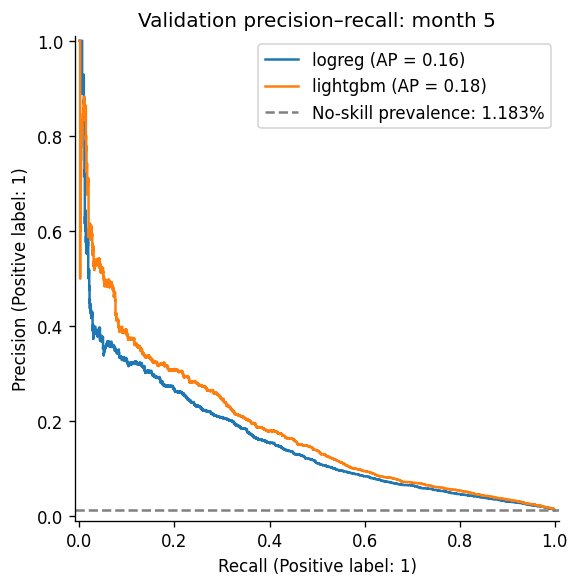

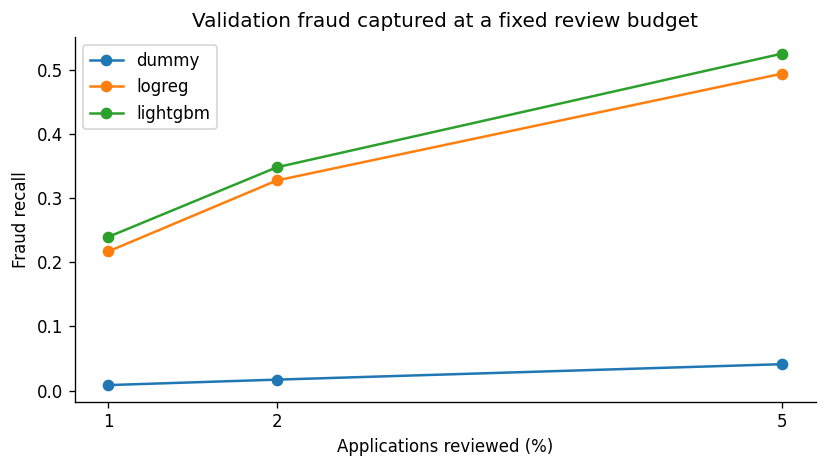

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

for model_name, scores in validation_scores.items():
    if model_name == 'dummy':
        continue

    PrecisionRecallDisplay.from_predictions(
        y_validation,
        scores,
        name=model_name,
        ax=ax,
    )

ax.axhline(
    y_validation.mean(),
    color='gray',
    linestyle='--',
    label=f'No-skill prevalence: {y_validation.mean():.3%}',
)
ax.set_title('Validation precision–recall: month 5')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'validation_precision_recall.png', bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))

for model_name, frame in validation_capacity.groupby('model', sort=False):
    ax.plot(
        100 * frame['capacity'],
        frame['recall'],
        marker='o',
        label=model_name,
    )

ax.set(
    xlabel='Applications reviewed (%)',
    ylabel='Fraud recall',
    title='Validation fraud captured at a fixed review budget',
)
ax.set_xticks([100 * value for value in REVIEW_CAPACITIES])
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'validation_review_capacity.png', bbox_inches='tight')
plt.show()
plt.close(fig)


## 9. Optional final test evaluation — disabled by default

Only enable this after the comparison plan is fixed. This evaluates **all selected baselines**, on pooled months 6–7 and each month separately, without changing their fitted pipelines or validation thresholds.

A test-set recall-at-FPR benchmark uses test labels retrospectively; columns prefixed `validation_threshold_` instead use the unchanged month-5 cutoff. Review-capacity tables contain exact top-K ranking; a separate table applies validation-capacity cutoffs unchanged. Do not keep changing model choices based on these test results.


In [ ]:
test_predictions = []

if not EVALUATE_TEST:
    print('Skipped: final test evaluation is disabled. Validation baseline work is complete.')
else:
    test_metric_rows = []
    test_capacity_frames = []
    test_fixed_capacity_rows = []
    scores_by_model = {
        model_name: estimator.predict_proba(test[FEATURES])[:, 1]
        for model_name, estimator in selected_models.items()
    }

    evaluation_periods = [('pooled_6_7', test)] + [
        (f'month_{month}', test[test[MONTH] == month])
        for month in manifest['split_months']['test']
    ]

    for period_name, frame in evaluation_periods:
        positions = test.index.get_indexer(frame.index)
        y_true = frame[TARGET].to_numpy()

        if len(np.unique(y_true)) != 2:
            raise ValueError(f'{period_name} needs both classes for ROC evaluation.')

        tie_breakers = np.random.default_rng(SEED).random(len(frame))

        for model_name in selected_models:
            scores = scores_by_model[model_name][positions]
            threshold = thresholds[model_name]['validation_fpr_threshold']
            operating_metrics = at_threshold(y_true, scores, threshold)

            test_metric_rows.append({
                'period': period_name,
                'model': model_name,
                'applications': len(frame),
                'fraud_rate': y_true.mean(),
                **ranking_metrics(y_true, scores, model_name),
                **{f'validation_threshold_{key}': value for key, value in operating_metrics.items()},
            })

            capacity = capacity_table(y_true, scores, REVIEW_CAPACITIES, tie_breakers)
            capacity.insert(0, 'model', model_name)
            capacity.insert(0, 'period', period_name)
            test_capacity_frames.append(capacity)

            for capacity_target, cutoff in thresholds[model_name]['validation_capacity_thresholds'].items():
                test_fixed_capacity_rows.append({
                    'period': period_name,
                    'model': model_name,
                    'validation_capacity_target': float(capacity_target),
                    **at_threshold(y_true, scores, cutoff),
                })

    test_metrics = pd.DataFrame(test_metric_rows)
    test_capacity = pd.concat(test_capacity_frames, ignore_index=True)
    test_fixed_capacity = pd.DataFrame(test_fixed_capacity_rows)

    test_metrics.to_csv(RESULTS_DIR / 'test_metrics.csv', index=False)
    test_capacity.to_csv(RESULTS_DIR / 'test_exact_capacity.csv', index=False)
    test_fixed_capacity.to_csv(RESULTS_DIR / 'test_fixed_validation_capacity_thresholds.csv', index=False)
    display(test_metrics.round(5))

    if SAVE_PREDICTIONS:
        for model_name, scores in scores_by_model.items():
            prediction_frame = test[[ROW_ID, MONTH, TARGET]].copy()
            prediction_frame['model'] = model_name
            prediction_frame['score'] = scores
            prediction_frame.to_parquet(
                ARTIFACTS_DIR / f'test_predictions_{model_name}.parquet',
                index=False,
            )


Skipped: final test evaluation is disabled. Validation baseline work is complete.


## 10. Persist the development record and reusable fitted pipelines

The manifest copy and settings identify the exact prepared dataset and run configuration. `selected_configs.json` contains settings and JSON-safe thresholds: an infinite no-alert cutoff is stored as `null` with its direction recorded. Reload it as positive infinity when applying that policy.

Saved joblib models contain their fitted sklearn preprocessing. Keep matching dependency versions when reloading. Load only joblib files you trust. These fitted **All history** preprocessors must not be reused for Recent K or Historical K: build a new pipeline and fit it on each subset.


In [ ]:
def json_safe(value):
    """
    Convert nested results into standards-compliant JSON values.
    Nonfinite floats become null; threshold direction is recorded separately below.
    """
    if isinstance(value, dict):
        return {key: json_safe(item) for key, item in value.items()}

    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]

    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None

    if isinstance(value, np.generic):
        return value.item()

    return value


threshold_records = {}

for model_name, values in thresholds.items():
    cutoff = values['validation_fpr_threshold']
    threshold_records[model_name] = {
        **values,
        'fpr_threshold_is_positive_infinity': bool(np.isposinf(cutoff)),
    }

run_info = {
    'run_name': RUN_NAME,
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'preparation_id': manifest['preparation_id'],
    'prepared_sha256': manifest['prepared_sha256'],
    'training_condition': 'All history: months 0–4',
    'class_imbalance_treatment': 'none',
    'selection_metric': 'validation average precision',
    'seed': SEED,
    'n_jobs': N_JOBS,
    'run_tuning': RUN_TUNING,
    'evaluate_test': EVALUATE_TEST,
    'fpr_target': FPR_TARGET,
    'review_capacities': REVIEW_CAPACITIES,
    'lgbm_trees': LGBM_TREES,
    'logreg_max_iter': LOGREG_MAX_ITER,
    'candidate_grid': CANDIDATES,
    'selected_fit_warnings': selected_warnings,
    'versions': {
        'python': platform.python_version(),
        'pandas': pd.__version__,
        'numpy': np.__version__,
        'scikit_learn': sklearn.__version__,
        'lightgbm': lightgbm.__version__,
        'joblib': joblib.__version__,
    },
}

selected_configurations = {
    'best_model_by_validation_ap': best_model_name,
    'parameters': selected_params,
    'thresholds': threshold_records,
}

for filename, payload in [
    ('run_info.json', run_info),
    ('selected_configs.json', selected_configurations),
    ('preparation_manifest.json', manifest),
]:
    with open(RESULTS_DIR / filename, 'w', encoding='utf-8') as handle:
        json.dump(json_safe(payload), handle, indent=2, ensure_ascii=False, allow_nan=False)

if SAVE_MODELS:
    for model_name, estimator in selected_models.items():
        joblib.dump(
            estimator,
            ARTIFACTS_DIR / f'{model_name}.joblib',
            compress=3,
        )

if SAVE_PREDICTIONS:
    for model_name, scores in validation_scores.items():
        prediction_frame = validation[[ROW_ID, MONTH, TARGET]].copy()
        prediction_frame['model'] = model_name
        prediction_frame['score'] = scores
        prediction_frame.to_parquet(
            ARTIFACTS_DIR / f'validation_predictions_{model_name}.parquet',
            index=False,
        )

print('Saved results:', RESULTS_DIR)
print('Saved artifacts:', ARTIFACTS_DIR)
print('Test evaluation performed:', EVALUATE_TEST)


Saved results: /content/drive/MyDrive/BT4012_grp_proj/results/baseline/unweighted_baseline_20261115T161531Z_103e88
Saved artifacts: /content/drive/MyDrive/BT4012_grp_proj/artifacts/baseline/unweighted_baseline_20261115T161531Z_103e88
Test evaluation performed: False


## 11. Write findings and agree on the next experiment

Fill this in after a real run:

| Question | Evidence to record |
|---|---|
| Does logistic regression beat the no-skill reference? | Validation AP and review-budget recall |
| Does LightGBM improve over logistic regression? | AP, recall at the same budget, fitting time |
| Are numerical issues present? | Recorded convergence warnings |
| What workload does a fixed threshold imply? | Alert rate, false positives and precision |
| Which configuration moves forward? | Validation-based justification and saved settings |

**Next:** keep the baseline configuration as a reference. Run the matched-size Recent K versus Historical K comparison with fresh preprocessing for each training subset. Hold weighting/sampling treatment fixed for that comparison. Examine imbalance treatments separately. Do not claim this single-seed baseline measures temporal or sampling uncertainty.

**Business interpretation:** flagged fraud labels are not proven fraud prevented; reviewed legitimate applications are not necessarily rejected customers. The data is synthetic and does not provide actual investigation costs or monetary savings.

**AI acknowledgement:** document the assistance used to produce the code and verify the analysis yourselves. [BAF documentation](https://github.com/feedzai/bank-account-fraud/tree/main/documents).
